# Taller 3 · Parte 3 — Prototipo aplicado: del Q-Learning tabular a una Deep Q-Network
**Sistema de Predicción de Enfermedad Cardíaca (triaje de infarto)** · Aprendizaje de Máquina · Universidad Sergio Arboleda
Juan Esteban Martínez · Sebastián Díaz · Jeancarlo Arturo Rodríguez Ladino

Este notebook **evoluciona el prototipo del Taller 2** (Q-Learning en triaje de infarto). Se conserva todo el problema
—mismo entorno, misma matriz de recompensa, mismas métricas e hiperparámetros— y solo se cambia el "cerebro" del agente:

| | Taller 1 (MDP) | Taller 2 (Q-Learning) | **Taller 3 (DQN)** |
|---|---|---|---|
| Estado | 4 grupos K-Means | 3 niveles de troponina (`qcut`) o 3 clústeres | **8 variables clínicas continuas** |
| Cómo decide | Iteración de valor (conoce P) | **Q-Table** 3×3 (aprende probando) | **Q-Network**: red neuronal que estima Q |
| Estabilidad | — | — | **Experience Replay + Red Objetivo** |

Acciones (iguales al Taller 2): **Verde** = seguimiento · **Amarillo** = repetir medición · **Rojo** = escalar.

| Resultado real | Verde | Amarillo | Rojo |
|---|---|---|---|
| Infarto | −50 | +2 | +10 |
| Sano | +5 | +0.5 | −3 |

**Pregunta del experimento:** si el agente ve al paciente completo en lugar de su "cajón", ¿reduce las 177 falsas alarmas del Taller 2 sin dejar pasar infartos?

In [1]:
# Funciona en Google Colab sin instalar nada: si Medicaldataset.csv no está en la carpeta, se descarga del repositorio del grupo.
import copy, os, random, time, urllib.request
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
RUTA_CSV = 'Medicaldataset.csv'
URL_CSV = 'https://raw.githubusercontent.com/jeancaladinoxb/MDP/EstadosbyJeancito/Medicaldataset.csv'
if not os.path.exists(RUTA_CSV):
    urllib.request.urlretrieve(URL_CSV, RUTA_CSV)
    print('Dataset descargado del repositorio del grupo')
CARPETA_SALIDA = 'resultados'
os.makedirs(CARPETA_SALIDA, exist_ok=True)
torch.set_num_threads(4)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

ACCIONES = ['Verde', 'Amarillo', 'Rojo']
COLOR = {'Verde': '#2e9e5b', 'Amarillo': '#e3a512', 'Rojo': '#d63b3b'}
MATRIZ_CLINICA = {
    (1, 'Verde'): -50.0, (1, 'Amarillo'): 2.0, (1, 'Rojo'): 10.0,   # paciente con infarto
    (0, 'Verde'):   5.0, (0, 'Amarillo'): 0.5, (0, 'Rojo'): -3.0,   # paciente sano
}
R_TABLA = np.array([[MATRIZ_CLINICA[(i, a)] for a in ACCIONES] for i in (0, 1)])  # R_TABLA[infarto, acción]

# Hiperparámetros del Taller 2 (se mantienen para que la comparación sea justa)
GAMMA, EPS_INI, EPS_MIN, DECAY, PASOS = 0.9, 1.0, 0.01, 0.999, 10000

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

fijar_semilla(SEED)
print('PyTorch', torch.__version__)

PyTorch 2.15.0


## 1. Datos
Se usa la limpieza del Taller 1 (se eliminan 5 pacientes con frecuencia cardíaca imposible) y, a diferencia del Taller 2,
se separa un **20 % de pacientes de prueba** que ningún agente ve al entrenar: así medimos si el agente **generaliza**.
El orden original del archivo se conserva, porque en el entorno del Taller 2 el siguiente estado es *el próximo paciente que llega*.

In [2]:
df = pd.read_csv(RUTA_CSV).rename(columns={
    'Age': 'age', 'Gender': 'gender', 'Heart rate': 'heart_rate',
    'Systolic blood pressure': 'systolic_bp', 'Diastolic blood pressure': 'diastolic_bp',
    'Blood sugar': 'blood_sugar', 'CK-MB': 'ck_mb', 'Troponin': 'troponin', 'Result': 'result'})
n0 = len(df)
df = df[(df.heart_rate >= 30) & (df.heart_rate <= 250)].reset_index(drop=True)
df['infarto'] = (df.result == 'positive').astype(int)
print(f'Pacientes: {n0} -> {len(df)} (5 con frecuencia cardíaca imposible eliminados, como en el Taller 1)')

FEATURES = ['age', 'gender', 'heart_rate', 'systolic_bp', 'diastolic_bp', 'blood_sugar', 'ck_mb', 'troponin']
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, stratify=df.infarto, random_state=SEED)
tr = df.loc[np.sort(idx_tr)].reset_index(drop=True)   # se conserva el orden de llegada
te = df.loc[np.sort(idx_te)].reset_index(drop=True)
print(f'Entrenamiento: {len(tr)} pacientes | Prueba: {len(te)} ({te.infarto.sum()} con infarto, {(te.infarto == 0).sum()} sanos)')

Pacientes: 1319 -> 1314 (5 con frecuencia cardíaca imposible eliminados, como en el Taller 1)
Entrenamiento: 1051 pacientes | Prueba: 263 (162 con infarto, 101 sanos)


## 2. Punto de partida: los agentes Q-Table del Taller 2
Se reconstruye el agente del Taller 2 sin cambios: episodios de un paso, ε-greedy y la actualización
`Q[s,a] ← Q[s,a] + α·(r + γ·max Q[s'] − Q[s,a])`, donde `s'` es el estado del siguiente paciente del archivo.
Se entrenan las dos definiciones de estado del Taller 2: **cuantiles de troponina** (base) y **K-Means K = 3** (Parte 3).

In [3]:
# --- Estados del Taller 2, ajustados solo con los pacientes de entrenamiento ---
_, CORTES_TROP = pd.qcut(tr.troponin, q=3, retbins=True)
CORTES_TROP[0], CORTES_TROP[-1] = -np.inf, np.inf
def estado_qcut(d):
    return np.digitize(d.troponin, CORTES_TROP[1:-1])          # 0 = Baja, 1 = Media, 2 = Alta

def log_marcadores(d):
    return np.log10(d[['troponin', 'ck_mb']].to_numpy() + 0.001)
escala_km = StandardScaler().fit(log_marcadores(tr))
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(escala_km.transform(log_marcadores(tr)))
def estado_kmeans(d):
    return kmeans.predict(escala_km.transform(log_marcadores(d)))

NOMBRES_QCUT = ['Troponina_Baja', 'Troponina_Media', 'Troponina_Alta']


def entrenar_q_table(estados, infartos, alpha=0.1, seed=SEED):
    # Mismo agente del Taller 2. El entorno elige un paciente real del estado s; s' = estado del siguiente paciente.
    rng = np.random.default_rng(seed)
    n = len(estados)
    siguientes = np.roll(estados, -1)[:-1]
    estados, infartos = estados[:-1], infartos[:-1]
    grupos = {s: np.flatnonzero(estados == s) for s in np.unique(estados)}
    Q = np.zeros((int(estados.max()) + 1, 3))
    eps, recompensas = EPS_INI, []
    for ep in range(PASOS):
        s = estados[rng.integers(len(estados))]
        a = int(rng.integers(3)) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
        i = grupos[s][rng.integers(len(grupos[s]))]
        r, s2 = R_TABLA[infartos[i], a], siguientes[i]
        Q[s, a] += alpha * (r + GAMMA * Q[s2].max() - Q[s, a])
        recompensas.append(r)
        eps = max(EPS_MIN, eps * DECAY)
    return Q, np.array(recompensas)

Q_qcut, rec_qcut = entrenar_q_table(estado_qcut(tr), tr.infarto.to_numpy())
Q_km, rec_km = entrenar_q_table(estado_kmeans(tr), tr.infarto.to_numpy())

t = pd.DataFrame(Q_qcut, index=NOMBRES_QCUT, columns=ACCIONES).round(1)
t['Política'] = [ACCIONES[a] for a in Q_qcut.argmax(1)]
t['% infarto'] = [f'{tr.infarto[estado_qcut(tr) == k].mean():.1%}' for k in range(3)]
print('Q-Table del Taller 2 (cuantiles de troponina), reentrenada con los pacientes de entrenamiento:')
t

Q-Table del Taller 2 (cuantiles de troponina), reentrenada con los pacientes de entrenamiento:


,Verde,Amarillo,Rojo,Política,% infarto
Troponina_Baja,36.0,43.6,40.1,Amarillo,25.2%
Troponina_Media,8.5,42.8,44.5,Rojo,55.4%
Troponina_Alta,-2.7,47.4,52.4,Rojo,99.7%


## 3. La evolución: Deep Q-Network
El estado deja de ser un "cajón": la red recibe **las 8 variables del paciente** (troponina, CK-MB y glucosa en log10, todas estandarizadas)
y devuelve el valor Q de Verde, Amarillo y Rojo. El entorno es el mismo del Taller 2: el agente decide sobre un paciente, recibe la
recompensa de la matriz clínica y el siguiente estado es el próximo paciente que llega.

Trucos de estabilidad (Parte 1 del taller):
* **Experience Replay:** memoria de 10 000 experiencias; se aprende de lotes de 64 tomados **al azar**.
* **Red Objetivo:** copia congelada que calcula `r + γ·max Q_objetivo(s')`; se sincroniza cada 250 pasos.

Las recompensas se dividen entre 10 al entrenar (escala numérica más cómoda para la red); todo se reporta en la escala original.

In [4]:
LOG_COLS = ['blood_sugar', 'ck_mb', 'troponin']

class Codificador:
    # Convierte pacientes en vectores para la red, aprendiendo la escala solo con los datos de entrenamiento.
    def __init__(self, d, columnas):
        self.columnas = columnas
        self.escala = StandardScaler().fit(self._crudo(d))
    def _crudo(self, d):
        Z = d[self.columnas].astype(float).copy()
        for c in LOG_COLS:
            if c in Z: Z[c] = np.log10(Z[c])
        return Z.to_numpy()
    def __call__(self, d):
        return self.escala.transform(self._crudo(d)).astype(np.float32)


class QNetwork(nn.Module):
    def __init__(self, n_entrada, n_acciones=3, oculta=64):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(n_entrada, oculta), nn.ReLU(),
            nn.Linear(oculta, oculta), nn.ReLU(),
            nn.Linear(oculta, n_acciones),
        )
    def forward(self, s):
        return self.red(s)


def entrenar_dqn(columnas=FEATURES, replay=True, red_objetivo=True, seed=SEED, lote=64, lr=1e-3,
                 sincronizar=250, capacidad=10000, escala_r=10.0):
    fijar_semilla(seed)
    rng = np.random.default_rng(seed)
    cod = Codificador(tr, columnas)
    S_all, inf_all = cod(tr), tr.infarto.to_numpy()
    n = len(S_all) - 1                                  # el último paciente no tiene "siguiente"

    q = QNetwork(S_all.shape[1])
    q_obj = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    # Sin replay: solo se recuerdan las últimas `lote` experiencias, en orden de llegada (datos correlacionados)
    memoria = deque(maxlen=capacidad if replay else lote)
    eps, recompensas, perdidas, q_medio = EPS_INI, [], [], []

    for t in range(PASOS):
        i = int(rng.integers(n))                        # llega un paciente
        s, s2 = S_all[i], S_all[i + 1]
        if rng.random() < eps:
            a = int(rng.integers(3))
        else:
            with torch.no_grad():
                a = int(q(torch.from_numpy(s)).argmax())
        r = R_TABLA[inf_all[i], a]
        memoria.append((s, a, r / escala_r, s2))
        recompensas.append(r)
        eps = max(EPS_MIN, eps * DECAY)

        if len(memoria) >= lote:
            muestra = [memoria[j] for j in rng.integers(len(memoria), size=lote)] if replay else list(memoria)
            S = torch.from_numpy(np.stack([m[0] for m in muestra]))
            A = torch.tensor([m[1] for m in muestra])
            R = torch.tensor([m[2] for m in muestra], dtype=torch.float32)
            S2 = torch.from_numpy(np.stack([m[3] for m in muestra]))
            q_sa = q(S).gather(1, A[:, None]).squeeze(1)
            with torch.no_grad():
                red = q_obj if red_objetivo else q      # sin red objetivo: el objetivo se mueve en cada paso
                objetivo = R + GAMMA * red(S2).max(1).values
            perdida = F.smooth_l1_loss(q_sa, objetivo)
            opt.zero_grad(); perdida.backward()
            nn.utils.clip_grad_norm_(q.parameters(), 10)
            opt.step()
            perdidas.append(perdida.item())
            q_medio.append(q_sa.mean().item() * escala_r)

        if red_objetivo and t % sincronizar == 0:
            q_obj.load_state_dict(q.state_dict())

    politica = lambda d: q(torch.from_numpy(cod(d))).argmax(1).numpy()
    return dict(red=q, codificador=cod, escala_r=escala_r, politica=politica, recompensas=np.array(recompensas),
                perdidas=np.array(perdidas), q_medio=np.array(q_medio))

t0 = time.time()
dqn = entrenar_dqn()
print(f'DQN entrenada en {time.time() - t0:.1f} s · {PASOS} pacientes · '
      f'{sum(p.numel() for p in dqn["red"].parameters())} parámetros (vs 9 celdas de la Q-Table)')

DQN entrenada en 5.7 s · 10000 pacientes · 4931 parámetros (vs 9 celdas de la Q-Table)


## 4. Evaluación con pacientes nuevos
Mismas métricas del Taller 2, calculadas sobre los pacientes de **prueba**.

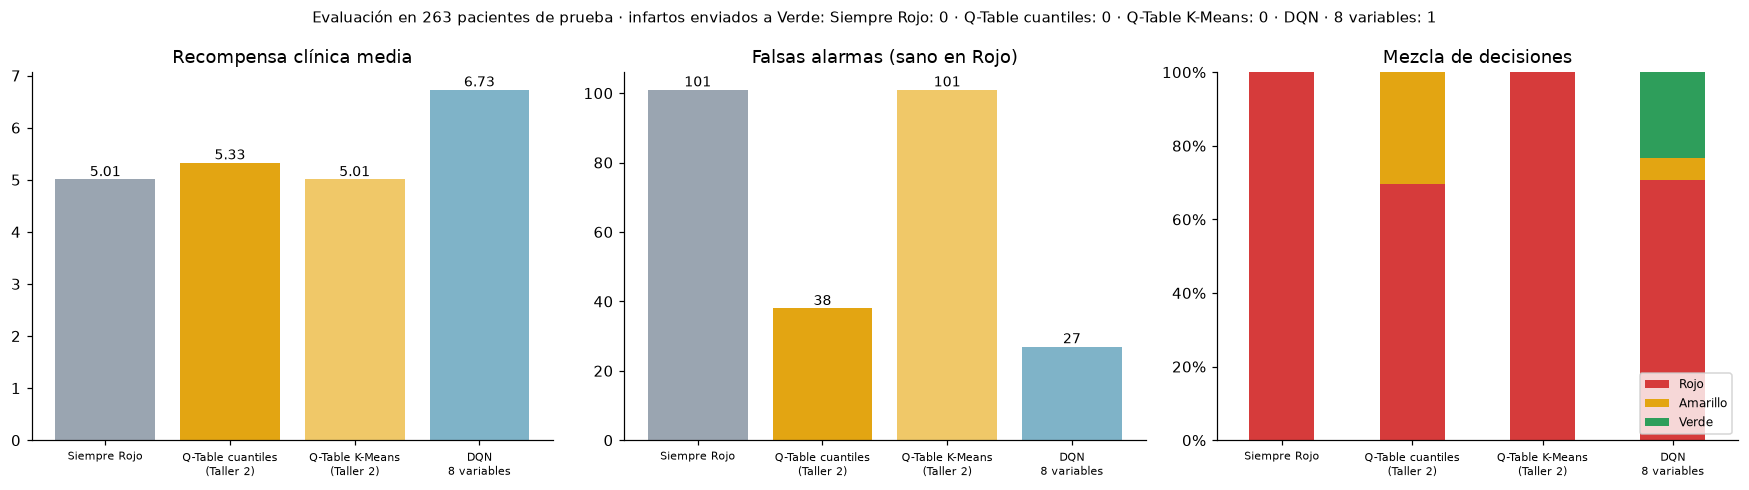

,Recompensa clínica media,Falsos negativos (infarto en Verde),Falsas alarmas (sano en Rojo),Infartos escalados a Rojo,Sanos en Verde,% Rojo,% Amarillo,% Verde
Siempre Rojo,5.007605,0,101,100%,0%,100%,0%,0%
Q-Table cuantiles (Taller 2),5.328897,0,38,90%,0%,70%,30%,0%
Q-Table K-Means (Taller 2),5.007605,0,101,100%,0%,100%,0%,0%
DQN · 8 variables,6.730038,1,27,98%,59%,71%,6%,23%


In [5]:
def evaluar(acciones, d):
    acc = np.array(ACCIONES)[acciones]
    inf = d.infarto.to_numpy() == 1
    rec = R_TABLA[d.infarto.to_numpy(), acciones]
    return pd.Series({
        'Recompensa clínica media': rec.mean(),
        'Falsos negativos (infarto en Verde)': int(((acc == 'Verde') & inf).sum()),
        'Falsas alarmas (sano en Rojo)': int(((acc == 'Rojo') & ~inf).sum()),
        'Infartos escalados a Rojo': f'{(acc[inf] == "Rojo").mean():.0%}',
        'Sanos en Verde': f'{(acc[~inf] == "Verde").mean():.0%}',
        '% Rojo': f'{(acc == "Rojo").mean():.0%}',
        '% Amarillo': f'{(acc == "Amarillo").mean():.0%}',
        '% Verde': f'{(acc == "Verde").mean():.0%}',
    })

PALETA = {'Siempre Rojo': '#9aa5b1', 'Q-Table cuantiles (Taller 2)': '#e3a512', 'Q-Table K-Means (Taller 2)': '#f0c868',
          'DQN · 8 variables': '#7fb3c8', 'DQN final · troponina + CK-MB': '#1c7293'}

def tabla_comparacion(decisiones, archivo):
    comp = pd.DataFrame({k: evaluar(v, te) for k, v in decisiones.items()}).T
    comp.to_csv(f'{CARPETA_SALIDA}/{archivo}.csv')
    return comp

def graficar_comparacion(decisiones, comp, archivo):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    nombres = [k.replace(' (', '\n(').replace(' · ', '\n') for k in comp.index]
    colores = [PALETA[k] for k in comp.index]
    for eje, col, fmt in zip(ax[:2], ['Recompensa clínica media', 'Falsas alarmas (sano en Rojo)'], ['%.2f', '%d']):
        b = eje.bar(nombres, comp[col].astype(float), color=colores)
        eje.bar_label(b, fmt=fmt, fontsize=9); eje.set_title(col); eje.tick_params(axis='x', labelsize=7.5)
    mezcla = pd.DataFrame({a: [(v == i).mean() for v in decisiones.values()] for i, a in enumerate(ACCIONES)}, index=nombres)
    mezcla[['Rojo', 'Amarillo', 'Verde']].plot.bar(stacked=True, ax=ax[2], rot=0,
                                                   color=[COLOR[c] for c in ('Rojo', 'Amarillo', 'Verde')])
    ax[2].set_title('Mezcla de decisiones'); ax[2].tick_params(axis='x', labelsize=7.5)
    ax[2].legend(fontsize=8, loc='lower right'); ax[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    fn = comp['Falsos negativos (infarto en Verde)']
    plt.suptitle(f'Evaluación en {len(te)} pacientes de prueba · infartos enviados a Verde: '
                 + ' · '.join(f'{k.split(" (")[0]}: {v}' for k, v in fn.items()), fontsize=9.5)
    plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/{archivo}.png', bbox_inches='tight'); plt.show()

with torch.no_grad():
    decisiones = {
        'Siempre Rojo': np.full(len(te), 2),
        'Q-Table cuantiles (Taller 2)': Q_qcut.argmax(1)[estado_qcut(te)],
        'Q-Table K-Means (Taller 2)': Q_km.argmax(1)[estado_kmeans(te)],
        'DQN · 8 variables': dqn['politica'](te),
    }
comparacion = tabla_comparacion(decisiones, '1_comparacion_inicial')
graficar_comparacion(decisiones, comparacion, '1_comparacion_inicial')
comparacion

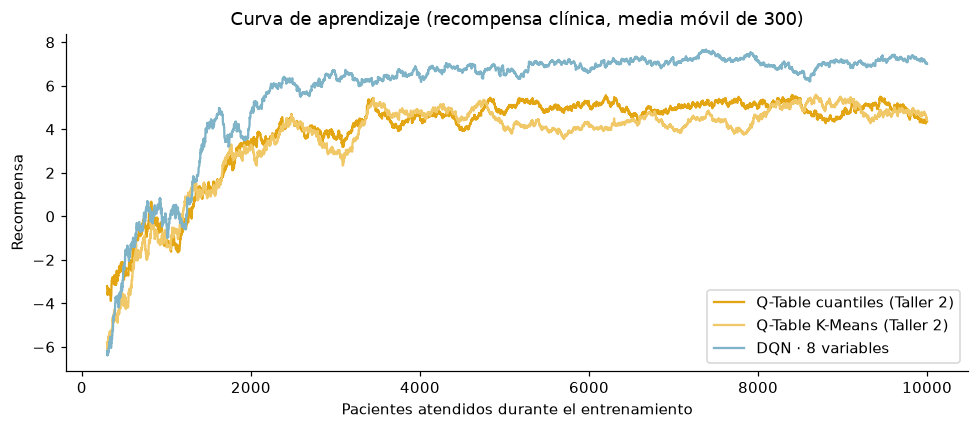

In [6]:
def media_movil(v, n=300):
    return pd.Series(v).rolling(n).mean()

fig, ax = plt.subplots(figsize=(9, 4))
for datos, nombre in ((rec_qcut, 'Q-Table cuantiles (Taller 2)'), (rec_km, 'Q-Table K-Means (Taller 2)'),
                      (dqn['recompensas'], 'DQN · 8 variables')):
    ax.plot(media_movil(datos), label=nombre, color=PALETA[nombre])
ax.set_title('Curva de aprendizaje (recompensa clínica, media móvil de 300)')
ax.set_xlabel('Pacientes atendidos durante el entrenamiento'); ax.set_ylabel('Recompensa'); ax.legend()
plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/2_curva_aprendizaje.png', bbox_inches='tight'); plt.show()

**Primera lectura:** la DQN ya supera a la Q-Table (más recompensa y menos falsas alarmas) y, a diferencia de ella, se atreve a usar
**Verde** con pacientes sanos. Pero dejó pasar **un infarto** a Verde, justo el error más costoso. Los experimentos siguientes buscan
entender por qué y corregirlo.

## 5. Experimentación
### 5.1 ¿Por qué hacen falta los trucos de estabilidad?
Tres variantes, 3 semillas cada una, mismos 10 000 pasos:
1. **DQN completa** (replay + red objetivo)
2. **Sin Experience Replay**: aprende solo de las últimas experiencias, en orden de llegada
3. **Sin Red Objetivo**: el objetivo `r + γ·max Q(s')` se calcula con la misma red que se está entrenando

In [7]:
SEMILLAS = [0, 1, 2]

def experimento(variantes):
    salida, filas = {}, []
    for nombre, cfg in variantes.items():
        evals = []
        for s in SEMILLAS:
            res = entrenar_dqn(seed=s, **cfg)
            with torch.no_grad():
                ev = evaluar(res['politica'](te), te)
            salida[(nombre, s)] = res; evals.append(ev)
        e = pd.DataFrame(evals)
        r = e['Recompensa clínica media'].astype(float)
        filas.append({'Variante': nombre,
                      'Recompensa clínica media': f'{r.mean():.2f} ± {r.std():.2f}',
                      'Falsos negativos (prom / máx)': f"{e['Falsos negativos (infarto en Verde)'].mean():.1f} / {e['Falsos negativos (infarto en Verde)'].max()}",
                      'Falsas alarmas (prom / máx)': f"{e['Falsas alarmas (sano en Rojo)'].mean():.1f} / {e['Falsas alarmas (sano en Rojo)'].max()}"})
    return salida, pd.DataFrame(filas).set_index('Variante')

t0 = time.time()
exp_estab, tabla_estab = experimento({
    'DQN completa': dict(),
    'Sin Experience Replay': dict(replay=False),
    'Sin Red Objetivo': dict(red_objetivo=False),
})
print(f'9 entrenamientos en {time.time() - t0:.0f} s')
tabla_estab.to_csv(f'{CARPETA_SALIDA}/experimento_estabilidad.csv')
tabla_estab

9 entrenamientos en 40 s


,Recompensa clínica media,Falsos negativos (prom / máx),Falsas alarmas (prom / máx)
Variante,,,
DQN completa,6.67 ± 0.24,0.3 / 1,19.0 / 27
Sin Experience Replay,5.48 ± 1.02,3.0 / 7,23.3 / 32
Sin Red Objetivo,6.67 ± 0.30,1.0 / 1,21.0 / 30


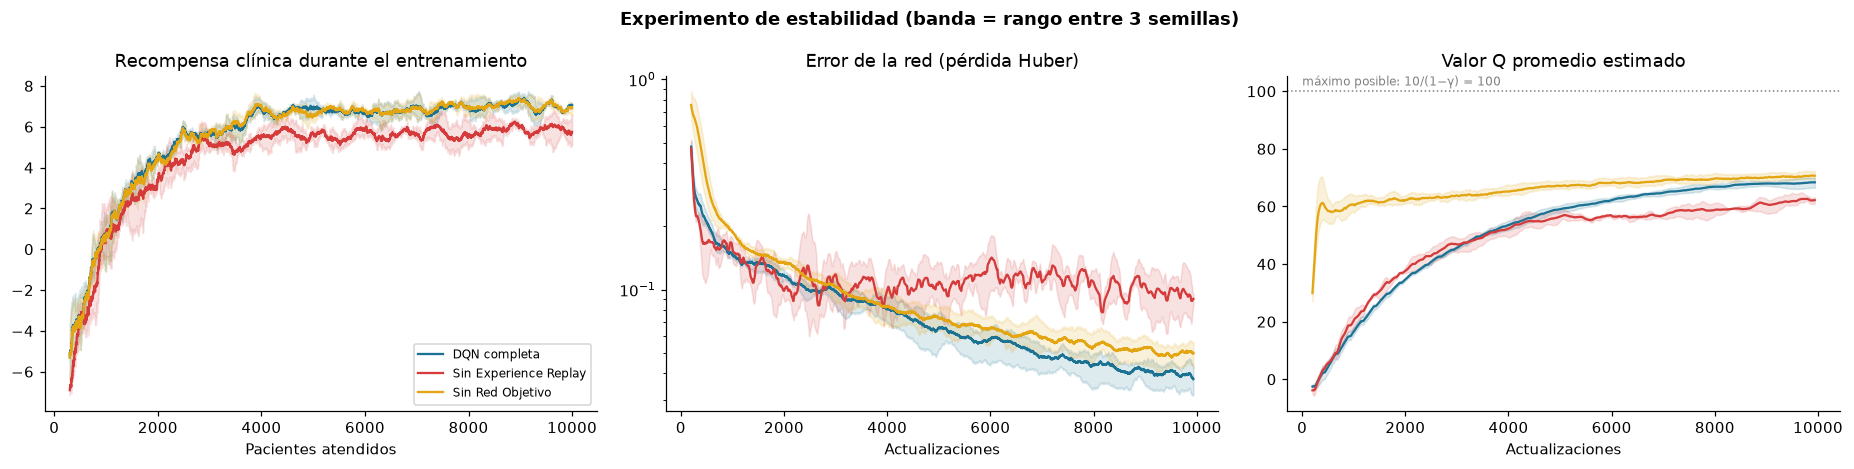

In [8]:
paleta = {'DQN completa': '#1c7293', 'Sin Experience Replay': '#d63b3b', 'Sin Red Objetivo': '#e3a512'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for nombre, color in paleta.items():
    for j, (clave, ventana) in enumerate((('recompensas', 300), ('perdidas', 200), ('q_medio', 200))):
        curvas = [media_movil(exp_estab[(nombre, s)][clave], ventana).to_numpy()[ventana:] for s in SEMILLAS]
        curvas = np.array([c[:min(map(len, curvas))] for c in curvas])
        x = np.arange(curvas.shape[1]) + ventana
        ax[j].plot(x, curvas.mean(0), color=color, label=nombre)
        ax[j].fill_between(x, curvas.min(0), curvas.max(0), color=color, alpha=0.15)
ax[0].set_title('Recompensa clínica durante el entrenamiento'); ax[0].set_xlabel('Pacientes atendidos')
ax[1].set_title('Error de la red (pérdida Huber)'); ax[1].set_xlabel('Actualizaciones'); ax[1].set_yscale('log')
ax[2].set_title('Valor Q promedio estimado'); ax[2].set_xlabel('Actualizaciones')
ax[2].axhline(10 / (1 - GAMMA), color='gray', ls=':', lw=1)
ax[2].text(0, 10 / (1 - GAMMA) * 1.02, 'máximo posible: 10/(1−γ) = 100', fontsize=8, color='gray')
ax[0].legend(fontsize=8)
plt.suptitle('Experimento de estabilidad (banda = rango entre 3 semillas)', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/4_trucos_estabilidad.png', bbox_inches='tight'); plt.show()

### 5.2 ¿De dónde sale la mejora: de ver valores continuos o de ver más variables?
Misma DQN, pero alimentada solo con **troponina y CK-MB** (la información que usaban los estados del Taller 2), frente a las **8 variables**.

In [9]:
exp_vars, tabla_vars = experimento({
    'DQN · troponina + CK-MB': dict(columnas=['troponin', 'ck_mb']),
    'DQN · 8 variables': dict(columnas=FEATURES),
})
tabla_vars.to_csv(f'{CARPETA_SALIDA}/experimento_variables.csv')
tabla_vars

,Recompensa clínica media,Falsos negativos (prom / máx),Falsas alarmas (prom / máx)
Variante,,,
DQN · troponina + CK-MB,7.89 ± 0.04,0.0 / 0,4.3 / 5
DQN · 8 variables,6.67 ± 0.24,0.3 / 1,19.0 / 27


## 6. Modelo final: DQN con troponina y CK-MB continuas
Con lo aprendido en la experimentación, el prototipo final usa la misma información que el Taller 2 (los dos marcadores),
pero **sin discretizarla**, con Experience Replay y Red Objetivo.

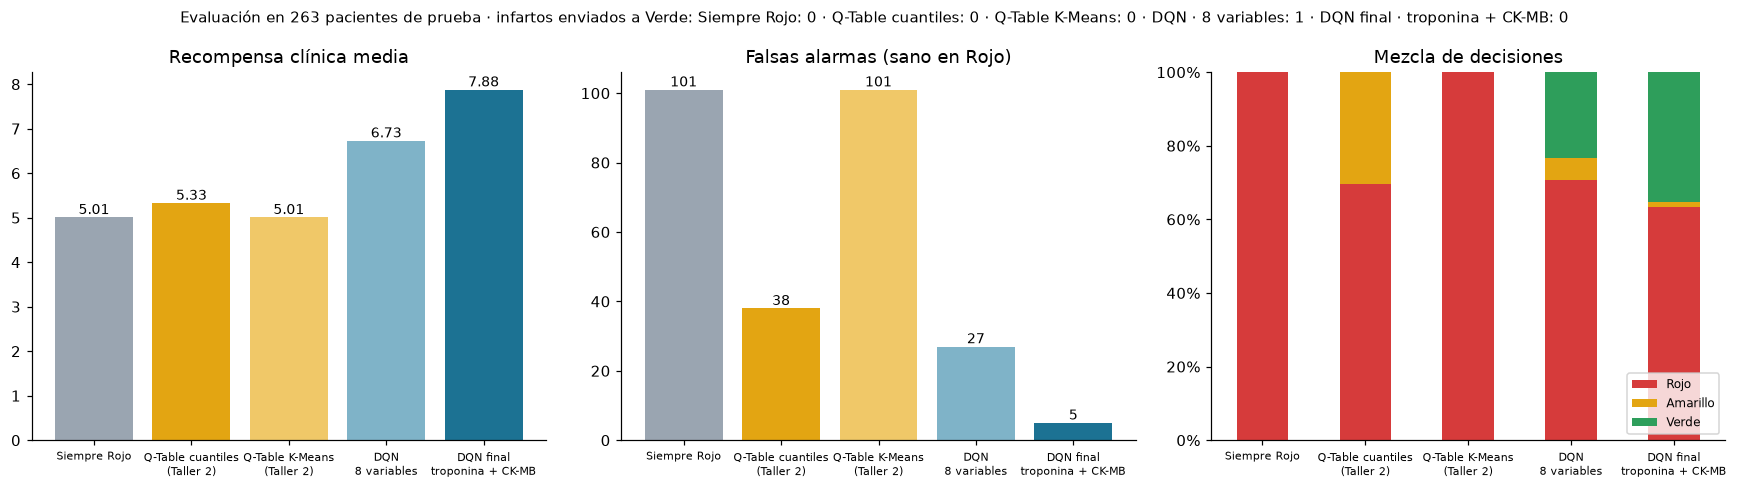

,Recompensa clínica media,Falsos negativos (infarto en Verde),Falsas alarmas (sano en Rojo),Infartos escalados a Rojo,Sanos en Verde,% Rojo,% Amarillo,% Verde
Siempre Rojo,5.007605,0,101,100%,0%,100%,0%,0%
Q-Table cuantiles (Taller 2),5.328897,0,38,90%,0%,70%,30%,0%
Q-Table K-Means (Taller 2),5.007605,0,101,100%,0%,100%,0%,0%
DQN · 8 variables,6.730038,1,27,98%,59%,71%,6%,23%
DQN final · troponina + CK-MB,7.876426,0,5,100%,92%,63%,1%,35%


In [10]:
MARCADORES = ['troponin', 'ck_mb']
dqn_final = entrenar_dqn(columnas=MARCADORES)
with torch.no_grad():
    decisiones['DQN final · troponina + CK-MB'] = dqn_final['politica'](te)
comparacion_final = tabla_comparacion(decisiones, '5_comparacion_final')
graficar_comparacion(decisiones, comparacion_final, '5_comparacion_final')
comparacion_final

### ¿Qué aprendió cada agente? Mapa de decisiones
Cada punto es un paciente de prueba ubicado por sus dos marcadores; el color es la decisión y la ✕ marca a quienes **sí** tenían infarto.
Las líneas grises son los cortes de los cuantiles del Taller 2: la Q-Table solo puede decidir por franjas de troponina,
mientras que la DQN traza su propia frontera usando ambos marcadores a la vez.

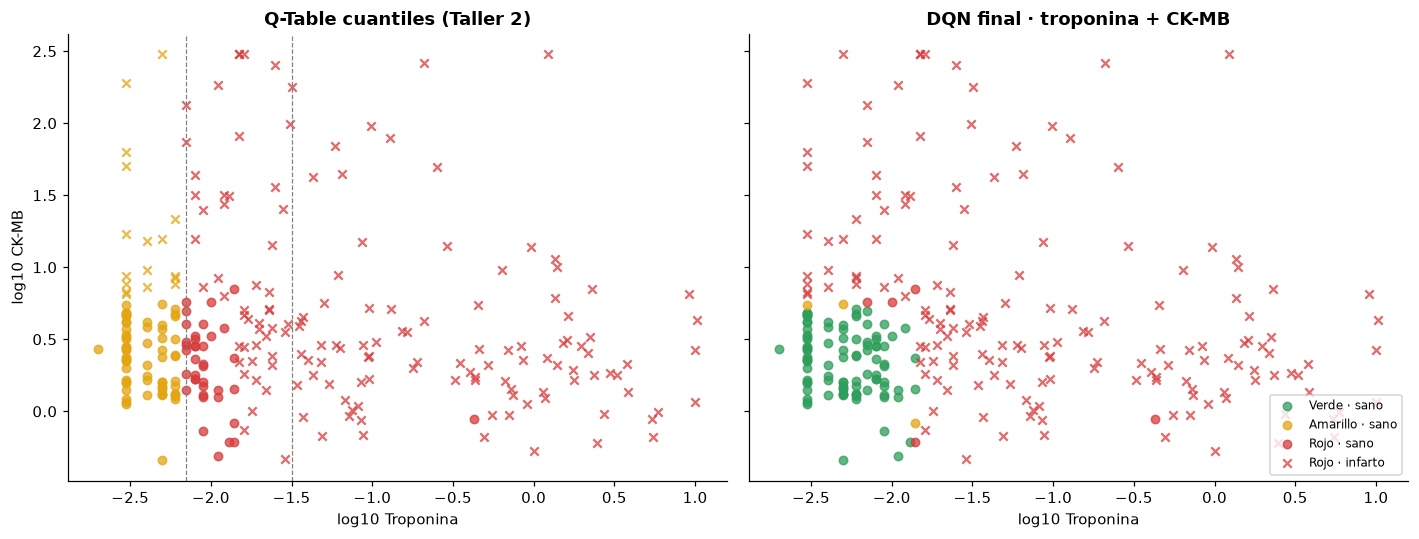

In [11]:
L = np.log10(te[['troponin', 'ck_mb']].to_numpy())
inf = te.infarto.to_numpy() == 1
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for eje, nombre in zip(ax, ['Q-Table cuantiles (Taller 2)', 'DQN final · troponina + CK-MB']):
    acc = np.array(ACCIONES)[decisiones[nombre]]
    for a in ACCIONES:
        for m, marca, txt in ((~inf, 'o', 'sano'), (inf, 'x', 'infarto')):
            sel = (acc == a) & m
            if sel.any():
                eje.scatter(L[sel, 0], L[sel, 1], c=COLOR[a], marker=marca, s=30, alpha=0.75, label=f'{a} · {txt}')
    eje.set_title(nombre, fontweight='bold'); eje.set_xlabel('log10 Troponina')
for c in CORTES_TROP[1:-1]:
    ax[0].axvline(np.log10(c), color='gray', ls='--', lw=0.8)
ax[0].set_ylabel('log10 CK-MB'); ax[1].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/6_mapa_decisiones.png', bbox_inches='tight'); plt.show()

## 7. Del prototipo al mockup
La app del mockup pide **troponina y CK-MB** (pantalla 1), muestra la predicción (pantalla 2) y permite la intervención humana (pantalla 3).
Esta función hace lo que haría la pantalla 2 con la DQN final: recibe los dos marcadores y devuelve el valor Q de cada color y la decisión.

Se prueban tres pacientes reales: un infarto evidente, un sano evidente y el **caso ambiguo del mockup** (troponina 0.005, CK-MB 0.676),
que parece sano pero tuvo infarto.

Infarto evidente          -> Rojo     | real: INFARTO | Q = Verde 19.1, Amarillo 70.9, Rojo 79.2
Sano evidente             -> Verde    | real: sano    | Q = Verde 73.6, Amarillo 70.1, Rojo 67.0
Caso ambiguo del mockup   -> Verde    | real: INFARTO | Q = Verde 73.2, Amarillo 68.8, Rojo 64.7


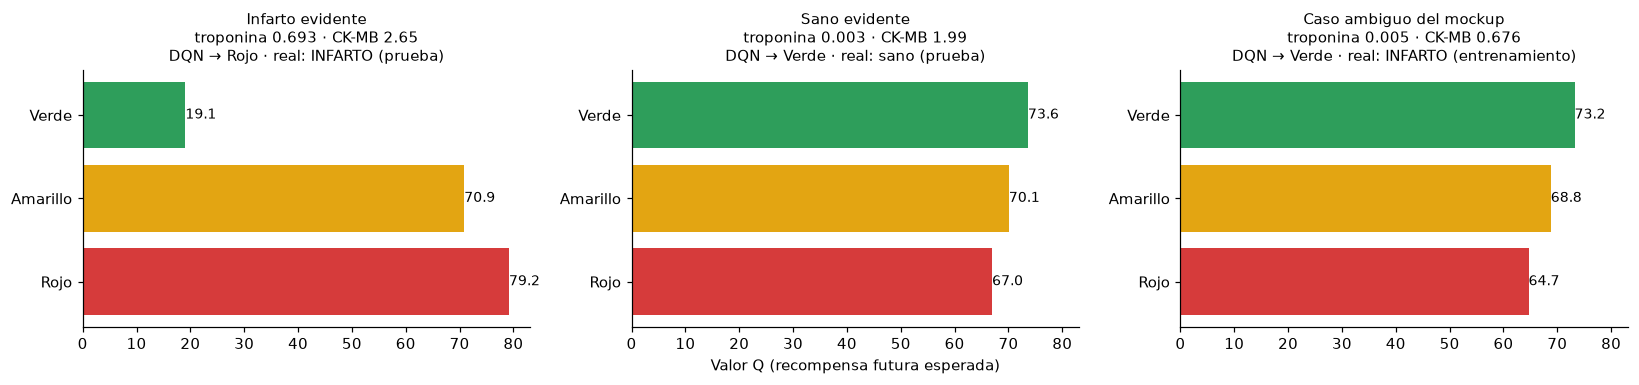

In [12]:
def triaje(troponina, ck_mb, modelo=dqn_final):
    d = pd.DataFrame({'troponin': [troponina], 'ck_mb': [ck_mb]})
    with torch.no_grad():
        q_vals = modelo['red'](torch.from_numpy(modelo['codificador'](d)))[0].numpy() * modelo['escala_r']
    return dict(zip(ACCIONES, q_vals)), ACCIONES[int(q_vals.argmax())]

def buscar(trop, ck):
    fila = df[(df.troponin == trop) & (df.ck_mb == ck)].iloc[0]
    return fila, ('prueba' if ((te.troponin == trop) & (te.ck_mb == ck)).any() else 'entrenamiento')

casos = {
    'Infarto evidente': (te[te.infarto == 1].sort_values('troponin').iloc[-40][['troponin', 'ck_mb']]),
    'Sano evidente': (te[te.infarto == 0].iloc[0][['troponin', 'ck_mb']]),
    'Caso ambiguo del mockup': pd.Series({'troponin': 0.005, 'ck_mb': 0.676}),
}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharex=True)
for eje, (nombre, v) in zip(ax, casos.items()):
    fila, conjunto = buscar(v.troponin, v.ck_mb)
    q_vals, decision = triaje(v.troponin, v.ck_mb)
    b = eje.barh(ACCIONES, list(q_vals.values()), color=[COLOR[a] for a in ACCIONES])
    eje.bar_label(b, fmt='%.1f', fontsize=9)
    real = 'INFARTO' if fila.infarto else 'sano'
    eje.set_title(f'{nombre}\ntroponina {v.troponin:g} · CK-MB {v.ck_mb:g}\nDQN → {decision} · real: {real} ({conjunto})', fontsize=10)
    eje.invert_yaxis()
    print(f'{nombre:25s} -> {decision:8s} | real: {real:7s} | Q = ' + ', '.join(f'{a} {q:.1f}' for a, q in q_vals.items()))
ax[1].set_xlabel('Valor Q (recompensa futura esperada)')
plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/7_demo_mockup.png', bbox_inches='tight'); plt.show()

## 8. Conclusiones

**1. La evolución funciona.** Con la misma matriz de recompensa y los mismos pacientes de prueba, la DQN final pasa de
**38 a 5 falsas alarmas** frente a la Q-Table del Taller 2, sube la recompensa clínica media de **5.33 a 7.88** y mantiene
**0 infartos enviados a Verde**. Además hace algo que la Q-Table nunca pudo: enviar a **Verde al 92 % de los sanos**, liberando
recursos de urgencias.

**2. El cambio clave es ver valores continuos, no más variables.** La Q-Table solo puede decidir por "cajones" de troponina, así que
un sano y un enfermo del mismo cajón reciben la misma acción. La DQN traza su propia frontera combinando troponina y CK-MB y
**generaliza** a pacientes que nunca vio. Darle las 8 variables empeoró el resultado (19 falsas alarmas en promedio y a veces un
infarto en Verde): con ~1 000 pacientes, las variables que casi no informan (ya lo mostraba el AdaBoost: troponina y CK-MB explican
~98 %) solo agregan ruido.

**3. Experience Replay es indispensable aquí.** Sin él la red aprende de pacientes consecutivos y correlacionados: la recompensa cae
a 5.48 ± 1.02, el error de la red no baja y en una semilla dejó pasar **7 infartos**. Con replay, el resultado es estable entre semillas.

**4. La Red Objetivo pesa poco en este entorno, y eso tiene explicación.** Como en el Taller 2, el siguiente paciente no depende de la
acción, así que el término `γ·max Q(s')` suma casi lo mismo a las tres acciones: cambia la escala de los valores Q (se ve el salto
inicial en la gráfica), pero no cuál acción gana. En problemas donde la acción sí cambia el futuro (como el MDP del Taller 1), su
efecto sería mayor.

**5. El caso del mockup muestra el límite ético.** El paciente ambiguo de la app (troponina 0.005, CK-MB 0.676) tuvo infarto y la DQN lo
envía a Verde: con marcadores normales, ningún modelo basado en ellos puede verlo. Por eso el sistema debe ser apoyo a la decisión, con
la **validación e intervención humana (override)** de la pantalla 3 del mockup.

> **Limitaciones:** dataset pequeño (1 314 pacientes), entorno simulado de un paso sin evolución real del paciente, matriz de
> recompensa de diseño propio y evaluación en un solo corte de prueba. Es un ejercicio académico, no un sistema clínico.